# CPL106 – Fourier Transform
## PH3120 – Computational Physics Laboratory

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


---
## Section 1: Basics of Sinewave Signals

### Signal definition
$$f(t) = A \sin(2\pi f t + \phi)$$

### Question I – Parameter Definitions

| Parameter | Symbol | Meaning | SI Unit |
|-----------|--------|---------|--------|
| Amplitude | $A$ | Peak magnitude of the signal from equilibrium | cm, V, Pa, etc. |
| Frequency | $f$ | Number of complete oscillations per second | Hz (s⁻¹) |
| Time | $t$ | Independent variable (time axis) | s |
| Phase | $\phi$ | Initial phase offset at $t = 0$; shifts the waveform along the time axis | radians |

### Question II – Relationship between Period $T$ and Frequency $f$

The **period** $T$ is the duration of one complete oscillation cycle. Since $f$ cycles occur per second:
$$T = \frac{1}{f}$$

Equivalently $f = 1/T$. The argument of the sine advances by $2\pi$ in one period, so $\omega = 2\pi f = 2\pi/T$.

### Question III – Relationship between $\phi$ and $f$

$\phi$ (phase) and $f$ (frequency) are **independent** parameters:
- $f$ controls *how fast* the signal oscillates (cycles per unit time).
- $\phi$ controls the *starting position* in the cycle at $t = 0$.

A phase shift of $\phi$ introduces a time delay $\tau = \phi / (2\pi f)$. At a fixed frequency, changing $\phi$ slides the waveform along the time axis without altering frequency or amplitude.

### Question IV – Importance of High Sampling Rate

When a continuous signal is sampled at rate $f_s$, the **Nyquist–Shannon theorem** requires:
$$f_s \geq 2 f_{\max}$$

- If $f_s < 2f_{\max}$: **aliasing** occurs — high-frequency content is misrepresented as lower frequencies, causing irreversible distortion.
- A higher sampling rate preserves the fine temporal detail of rapid oscillations.
- In audio, communications, and medical instrumentation, insufficient $f_s$ leads to unrecoverable information loss.

### Question V – Plotting at Different Sampling Frequencies

Given: $A = 10$ cm, $f = 50$ Hz, $\phi = \pi/6$

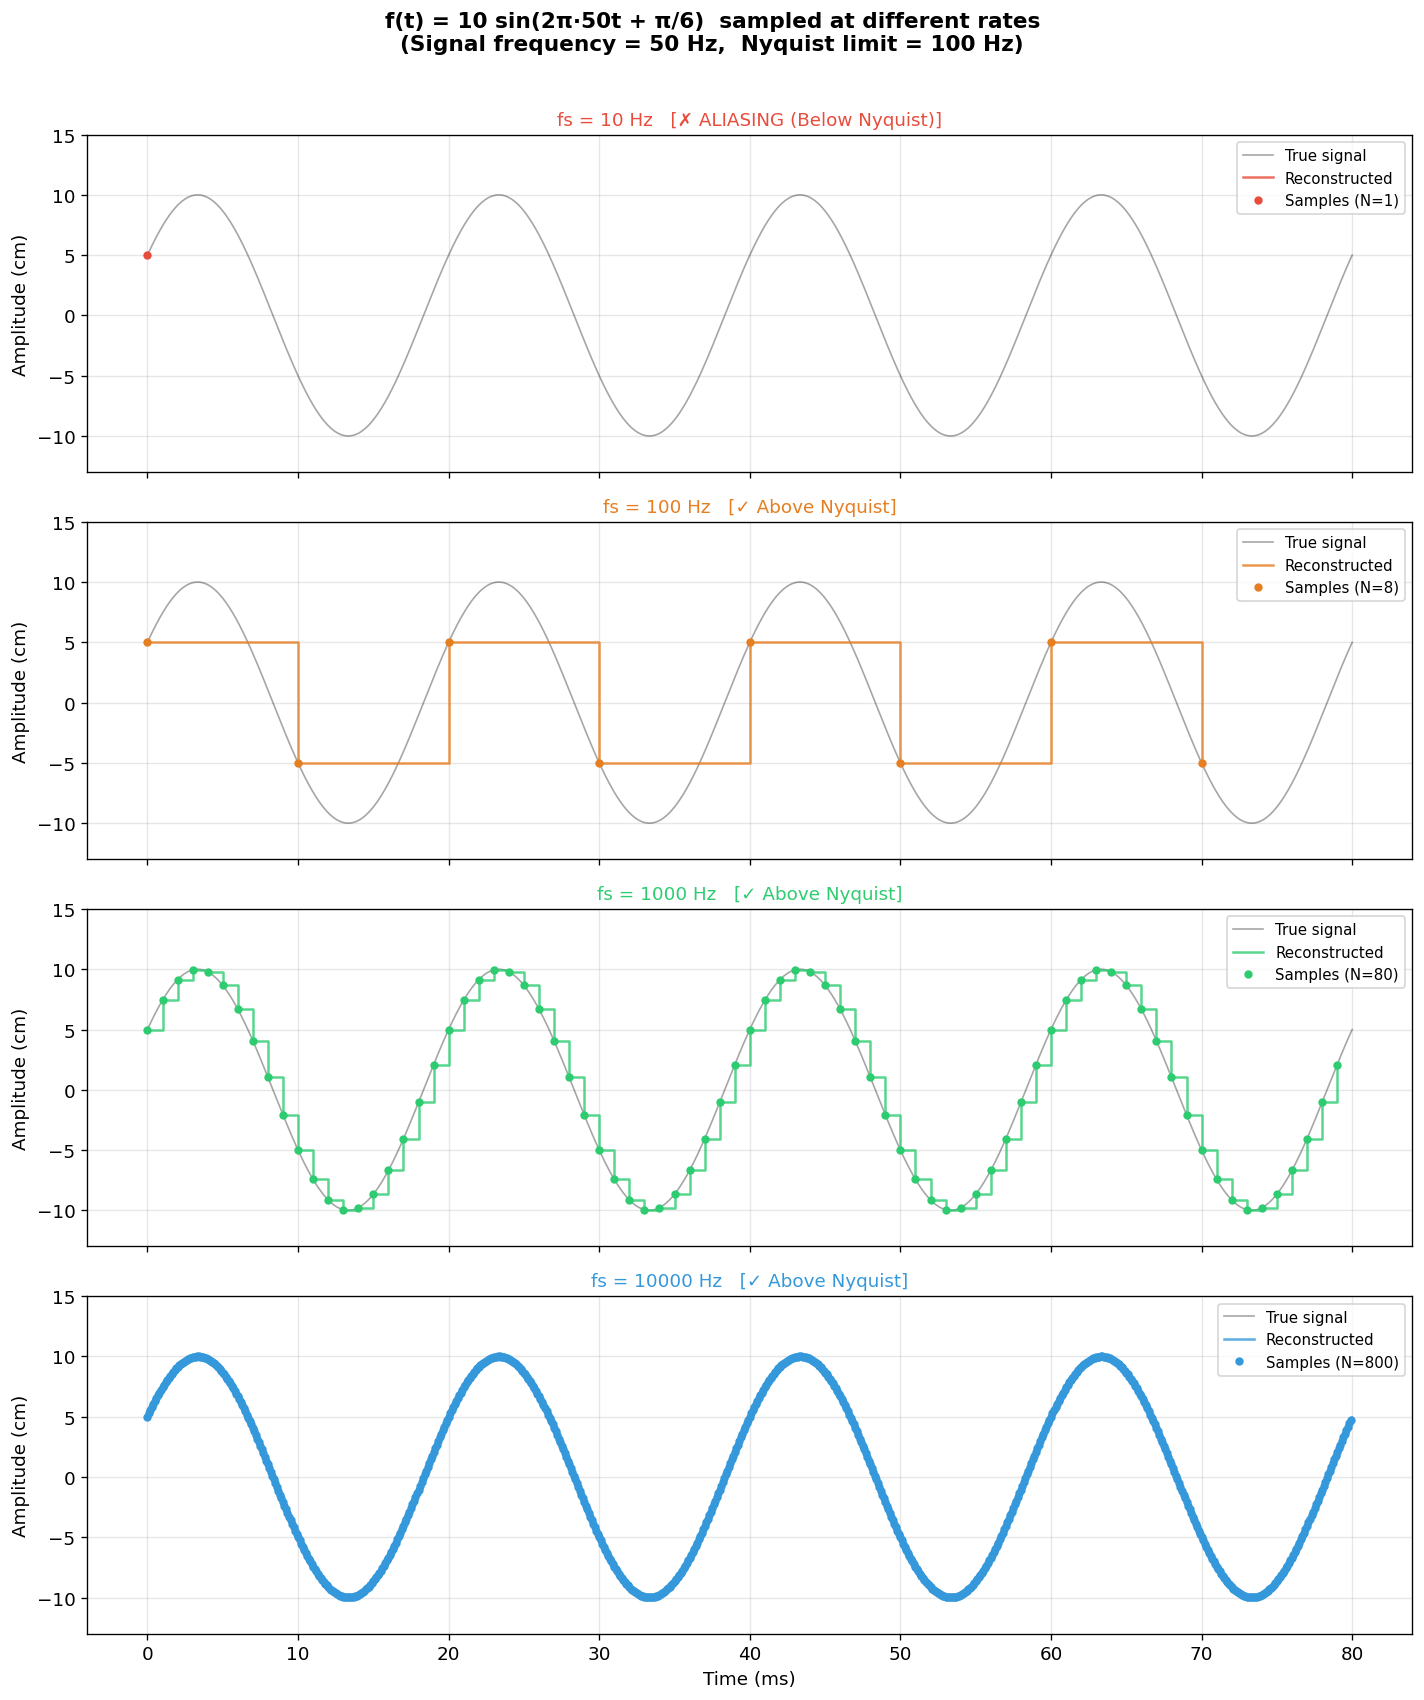

In [2]:
# Signal parameters
A     = 10            # amplitude (cm)
f_sig = 50            # signal frequency (Hz)
phi   = np.pi / 6     # phase (rad)

n_cycles = 4
T_sig    = 1 / f_sig
t_end    = n_cycles * T_sig   # 0.08 s

t_true = np.linspace(0, t_end, 10000)
y_true = A * np.sin(2 * np.pi * f_sig * t_true + phi)

sampling_freqs = [10, 100, 1000, 10000]
colors         = ['#e74c3c', '#e67e22', '#2ecc71', '#3498db']

fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)
fig.suptitle(
    f'f(t) = {A} sin(2π·{f_sig}t + π/6)  sampled at different rates\n'
    f'(Signal frequency = {f_sig} Hz,  Nyquist limit = {2*f_sig} Hz)',
    fontsize=13, fontweight='bold', y=1.01
)

for ax, fs, color in zip(axes, sampling_freqs, colors):
    t_s = np.arange(0, t_end, 1 / fs)
    y_s = A * np.sin(2 * np.pi * f_sig * t_s + phi)

    ax.plot(t_true * 1000, y_true, 'k-', lw=1, alpha=0.35, label='True signal')
    ax.step(t_s * 1000, y_s, where='post', color=color, lw=1.5, alpha=0.8, label='Reconstructed')
    ax.plot(t_s * 1000, y_s, 'o', color=color, ms=4, zorder=5, label=f'Samples (N={len(t_s)})')

    nyquist_ok = "✓ Above Nyquist" if fs >= 2 * f_sig else "✗ ALIASING (Below Nyquist)"
    ax.set_title(f'fs = {fs} Hz   [{nyquist_ok}]', fontsize=11, color=color)
    ax.set_ylabel('Amplitude (cm)')
    ax.set_ylim(-13, 15)
    ax.legend(loc='upper right', fontsize=9)

axes[-1].set_xlabel('Time (ms)')
plt.tight_layout()
plt.savefig('q1_sampling.png', bbox_inches='tight', dpi=150)
plt.show()


#### Comment on Results

| Sampling Freq | Samples / period | Observation |
|:---:|:---:|:---|
| **10 Hz** | 0.2 | Far below Nyquist (need ≥ 100 Hz). Severe **aliasing** — reconstructed waveform bears no resemblance to the original 50 Hz signal. |
| **100 Hz** | 2 | Exactly at Nyquist. Signal is technically recoverable but crude with only 2 samples/cycle. |
| **1000 Hz** | 20 | 10× oversampling. Reconstructed waveform closely tracks the true signal. Practical engineering choice. |
| **10000 Hz** | 200 | 100× oversampling. Near-perfect reconstruction. |

**Conclusion:** At least $f_s \geq 2f$ is required (Nyquist). In practice **5–10× oversampling** is preferred to allow for anti-aliasing filter roll-off and accurate amplitude/phase reproduction.

---
## Section 2: Discrete Fourier Transform (DFT)

### Question I – Time Domain

The **time domain** represents a signal as a function of time, $f(t)$ (or $f[n]$ for discrete sequences).
It describes *when* events occur and the instantaneous amplitude at each moment.
Most signals are naturally observed in the time domain (e.g., voltage on an oscilloscope).

### Question II – Frequency Domain and Fourier Transform

The **frequency domain** represents a signal as a function of frequency rather than time.
It answers: how much of each frequency $f$ is present in the signal?
Each spectral point gives the **amplitude** and **phase** of the sinusoid at that frequency.

The **Fourier Transform** is the mathematical bridge: it decomposes any signal into sinusoids of
different frequencies, transforming the perspective from time to frequency.
The result is the **spectrum** of the signal.

### Question III – Continuous vs Discrete Fourier Transform

| Aspect | Continuous FT (CFT) | Discrete FT (DFT) |
|--------|---------------------|-------------------|
| Input | Continuous, defined for all $t \in \mathbb{R}$ | Finite sequence of $N$ samples |
| Output | Continuous function of $f$ | Discrete sequence of $N$ complex values |
| Operation | Integral over $(-\infty,+\infty)$ | Finite sum over $N$ samples |
| Use | Analytical / closed-form | Numerical / computational |
| Freq. resolution | Infinitely fine | $\Delta f = f_s / N$ |

#### (a) DFT expression (discrete → frequency domain)

$$X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j\,2\pi kn/N}, \qquad k = 0, 1, \ldots, N-1$$

where $x[n]$ are $N$ discrete samples and $f_k = k\,f_s/N$.

#### (b) CFT expression (continuous → frequency domain)

$$X(f) = \int_{-\infty}^{+\infty} x(t)\, e^{-j\,2\pi f t}\, dt$$

---
## Section 3: Fast Fourier Transform (FFT)

### Question I – Advantages of FFT over DFT

The **FFT** exploits symmetry and periodicity of $e^{-j2\pi kn/N}$ to eliminate redundant multiplications.

| Aspect | DFT (naïve) | FFT (Cooley–Tukey) |
|--------|-------------|-------------------|
| Complexity | $O(N^2)$ | $O(N \log_2 N)$ |
| Ops for $N=10^6$ | $\sim 10^{12}$ | $\sim 2\times10^7$ |
| Speed-up | 1× | $\approx N/\log_2 N$ |
| Mathematical result | Exact DFT | **Identical** to DFT |

**Key advantages:**
1. **Speed:** For $N=1024$, FFT is ~100× faster. At $N=10^6$, speed-up exceeds $50{,}000\times$.
2. **Enables real-time processing** in audio, communications, MRI, radar, JPEG compression.
3. **Not an approximation** — produces exactly the same result as the DFT.

### Question II – Superposition of Two Sine Waves

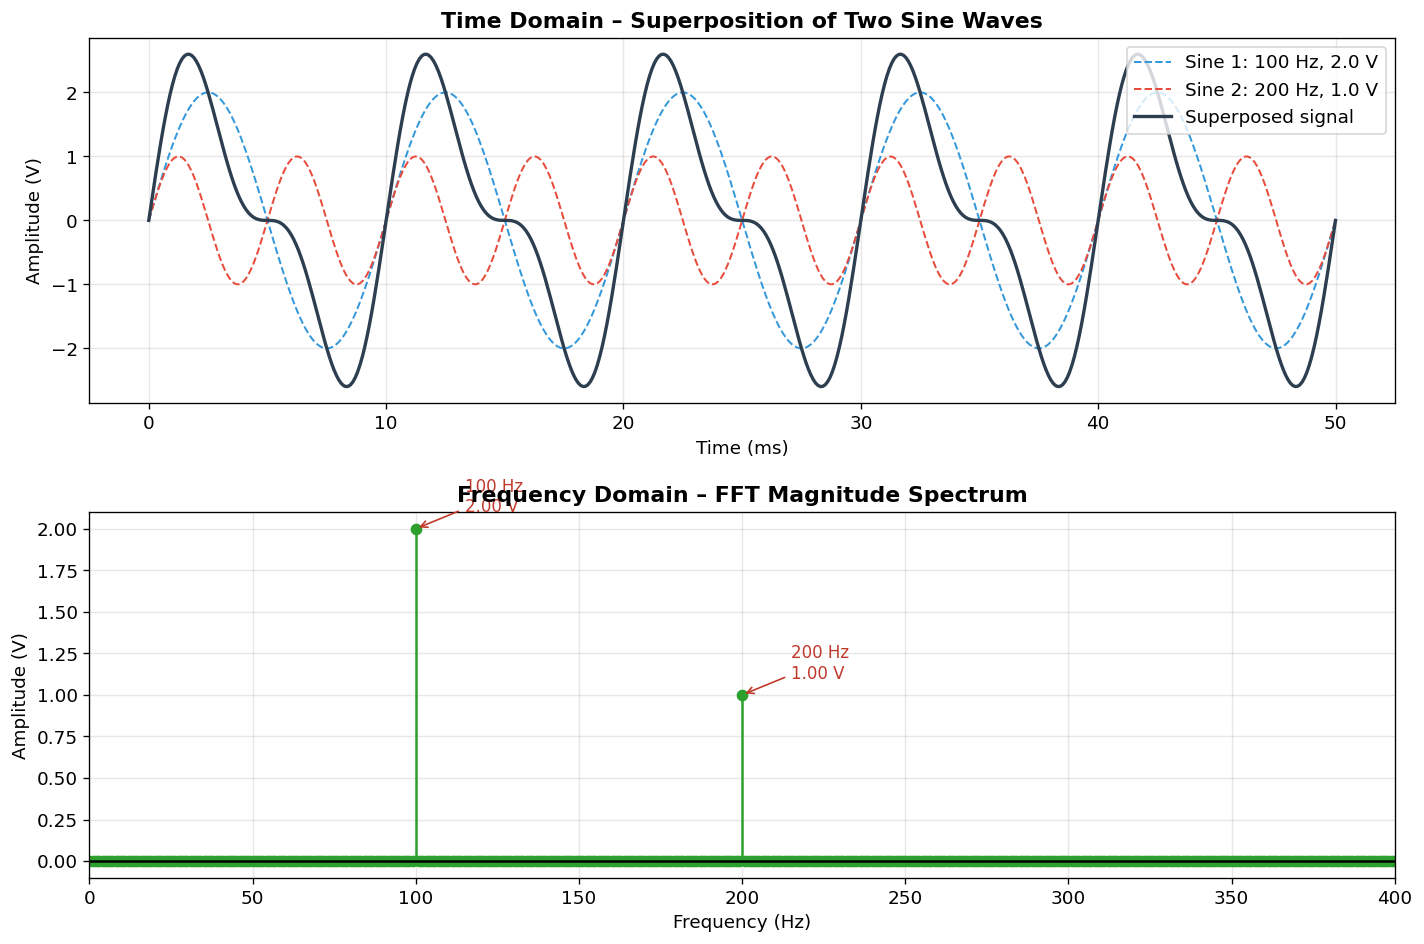

FFT peaks: [('100.0 Hz', '2.000 V'), ('200.0 Hz', '1.000 V')]


In [3]:
# Parameters
fs    = 10000
T     = 1.0
N     = int(fs * T)
t     = np.arange(N) / fs

f1, A1 = 100, 2.0
f2, A2 = 200, 1.0

s1 = A1 * np.sin(2 * np.pi * f1 * t)
s2 = A2 * np.sin(2 * np.pi * f2 * t)
s  = s1 + s2

# FFT
S     = np.fft.rfft(s)
freqs = np.fft.rfftfreq(N, 1/fs)
mag   = np.abs(S) / N
mag[1:-1] *= 2

# ── Plots ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

mask = t <= 0.05
axes[0].plot(t[mask]*1000, s1[mask], '--', color='#3498db', lw=1.2, label=f'Sine 1: {f1} Hz, {A1} V')
axes[0].plot(t[mask]*1000, s2[mask], '--', color='#e74c3c', lw=1.2, label=f'Sine 2: {f2} Hz, {A2} V')
axes[0].plot(t[mask]*1000, s[mask],  '-',  color='#2c3e50', lw=2,   label='Superposed signal')
axes[0].set_title('Time Domain – Superposition of Two Sine Waves', fontweight='bold')
axes[0].set_xlabel('Time (ms)')
axes[0].set_ylabel('Amplitude (V)')
axes[0].legend()

axes[1].stem(freqs, mag, markerfmt='C2o', linefmt='C2-', basefmt='k-')
axes[1].set_xlim(0, 400)
axes[1].set_title('Frequency Domain – FFT Magnitude Spectrum', fontweight='bold')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Amplitude (V)')

for ef, ea in [(f1, A1), (f2, A2)]:
    idx = np.argmin(np.abs(freqs - ef))
    axes[1].annotate(
        f'{ef} Hz\n{mag[idx]:.2f} V',
        xy=(freqs[idx], mag[idx]),
        xytext=(freqs[idx]+15, mag[idx]+0.1),
        fontsize=10, color='#c0392b',
        arrowprops=dict(arrowstyle='->', color='#c0392b')
    )

plt.tight_layout()
plt.savefig('q3_ii_superposition_fft.png', bbox_inches='tight', dpi=150)
plt.show()
print("FFT peaks:", [(f"{freqs[np.argmin(np.abs(freqs-ef))]:.1f} Hz",
                      f"{mag[np.argmin(np.abs(freqs-ef))]:.3f} V") for ef in [f1, f2]])


#### Comment on Results

The FFT magnitude spectrum shows **exactly two peaks** at **100 Hz (≈ 2.0 V)** and **200 Hz (≈ 1.0 V)**,
perfectly matching the input sine waves. This confirms:
1. The FFT correctly **decomposes** the superposed waveform into its constituent components.
2. Recovered amplitudes match the input amplitudes, validating the normalisation ($\div N$, one-sided $\times 2$).
3. No spurious frequency components appear, as expected for a noise-free synthetic signal.

---
### Question III – Amplitude Modulation (AM) with Single-Tone Message

#### (a) Carrier wave
$$c(t) = 5\sin(2\pi \cdot 500\, t)$$

#### (b) Modulating (message) signal
$$m(t) = 2\sin(2\pi \cdot 50\, t)$$

#### (c) AM wave function
Standard AM: $s(t) = [A_c + m(t)]\sin(2\pi f_c t)$
$$s(t) = [5 + 2\sin(2\pi \cdot 50\, t)]\sin(2\pi \cdot 500\, t)$$

Expanding with product-to-sum identity $\sin A\sin B = \frac{1}{2}[\cos(A-B)-\cos(A+B)]$:
$$s(t) = 5\sin(2\pi\cdot500\,t) + \cos(2\pi\cdot450\,t) - \cos(2\pi\cdot550\,t)$$

Expected frequency components: **450 Hz, 500 Hz, 550 Hz**

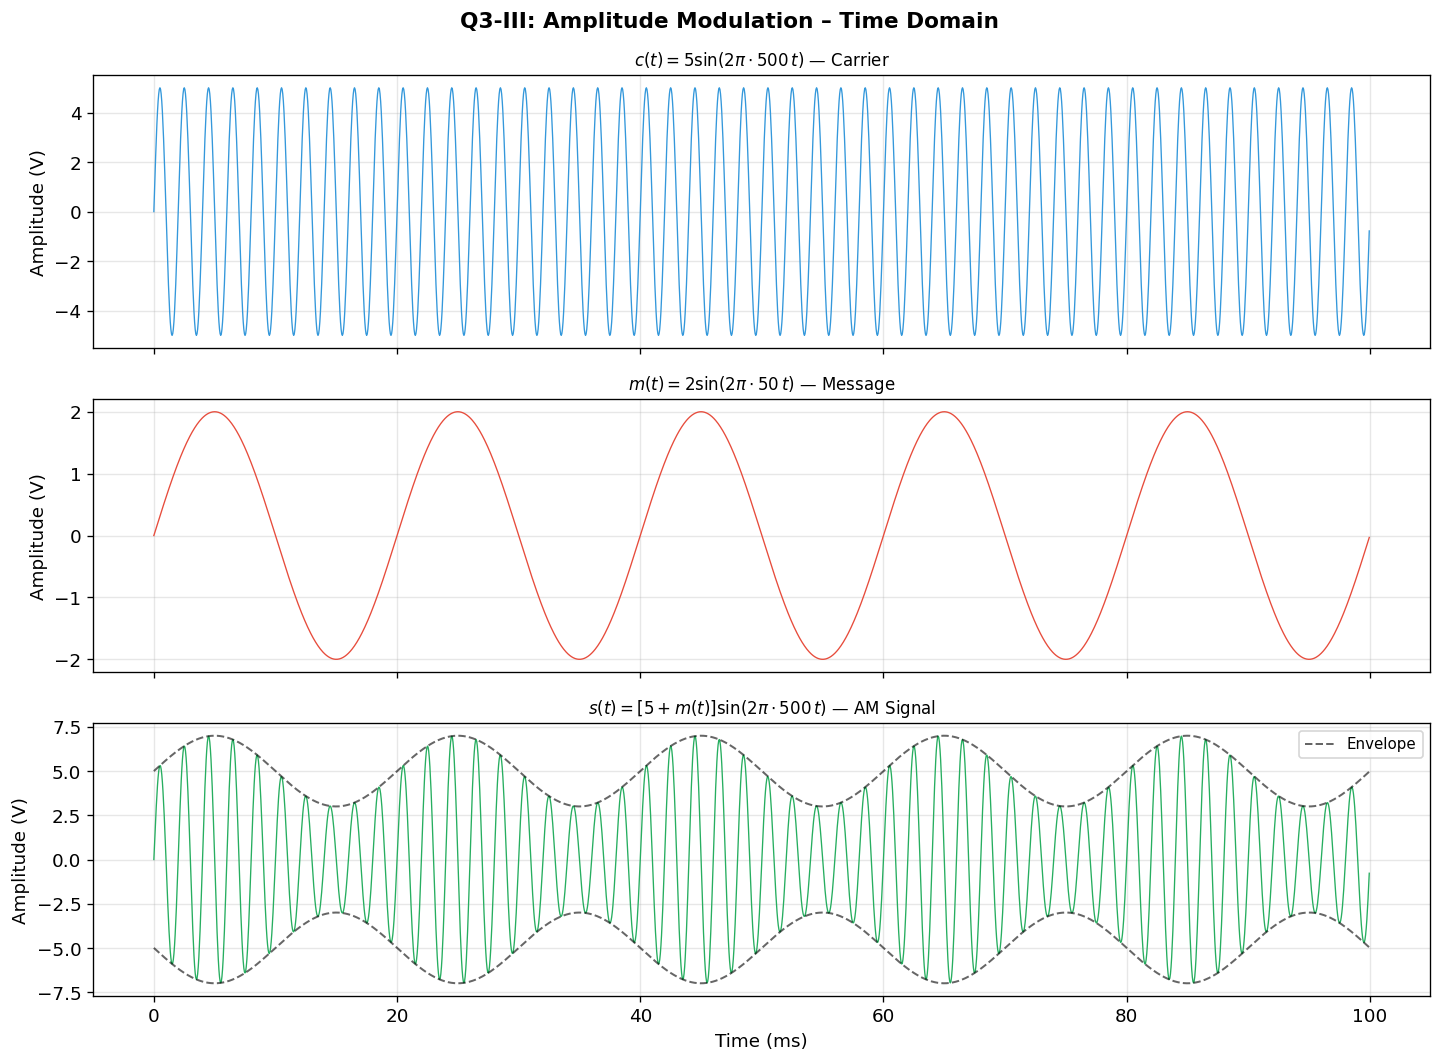

In [4]:
# Parameters
f_c, A_c = 500, 5.0
f_m, A_m = 50,  2.0

fs3 = 20000
t3  = np.linspace(0, 0.1, int(fs3 * 0.1), endpoint=False)

c_t = A_c * np.sin(2 * np.pi * f_c * t3)
m_t = A_m * np.sin(2 * np.pi * f_m * t3)
s_t = (A_c + m_t) * np.sin(2 * np.pi * f_c * t3)

# (d) Time domain
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
fig.suptitle('Q3-III: Amplitude Modulation – Time Domain', fontweight='bold', fontsize=13)

for ax, y, lbl, col in zip(axes,
    [c_t, m_t, s_t],
    [r'$c(t) = 5\sin(2\pi\cdot500\,t)$ — Carrier',
     r'$m(t) = 2\sin(2\pi\cdot50\,t)$ — Message',
     r'$s(t) = [5+m(t)]\sin(2\pi\cdot500\,t)$ — AM Signal'],
    ['#3498db','#e74c3c','#27ae60']):
    ax.plot(t3*1000, y, color=col, lw=0.8)
    ax.set_title(lbl, fontsize=10)
    ax.set_ylabel('Amplitude (V)')

axes[2].plot(t3*1000,  (A_c+m_t), 'k--', lw=1.2, alpha=0.6, label='Envelope')
axes[2].plot(t3*1000, -(A_c+m_t), 'k--', lw=1.2, alpha=0.6)
axes[2].legend(fontsize=9)
axes[2].set_xlabel('Time (ms)')
plt.tight_layout()
plt.savefig('q3_iii_d_time.png', bbox_inches='tight', dpi=150)
plt.show()


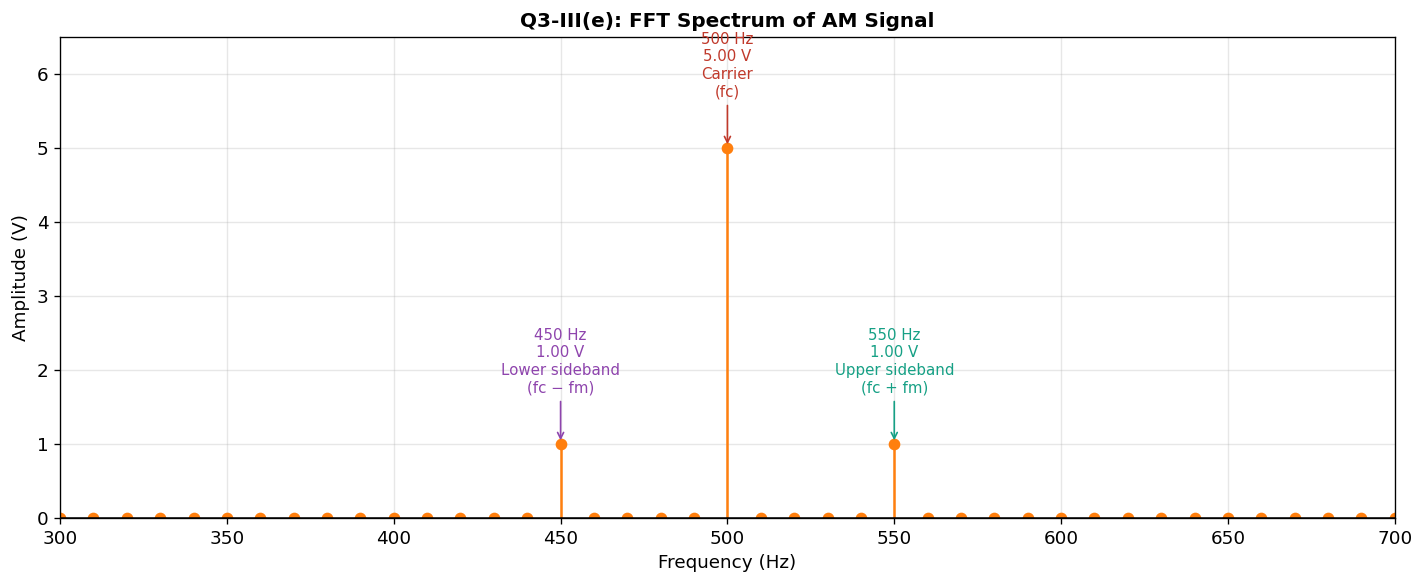

(ii)  Lowest  frequency : 450 Hz
(iii) Highest frequency : 550 Hz
(iv)  Bandwidth         : 100 Hz  (= 2 x f_m = 2 x 50)


In [5]:
# (e) FFT of AM signal
N3   = len(s_t)
S3   = np.fft.rfft(s_t)
f3   = np.fft.rfftfreq(N3, 1/fs3)
mag3 = np.abs(S3) / N3
mag3[1:-1] *= 2

fig, ax = plt.subplots(figsize=(12, 5))
ax.stem(f3, mag3, markerfmt='C1o', linefmt='C1-', basefmt='k-')
ax.set_xlim(300, 700)
ax.set_ylim(0, 6.5)
ax.set_title('Q3-III(e): FFT Spectrum of AM Signal', fontweight='bold', fontsize=12)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Amplitude (V)')

ann = {
    450: ('Lower sideband\n(fc − fm)', '#8e44ad'),
    500: ('Carrier\n(fc)',             '#c0392b'),
    550: ('Upper sideband\n(fc + fm)', '#16a085'),
}
for ef, (lbl, col) in ann.items():
    idx = np.argmin(np.abs(f3 - ef))
    ax.annotate(f'{ef} Hz\n{mag3[idx]:.2f} V\n{lbl}',
                xy=(f3[idx], mag3[idx]), xytext=(f3[idx], mag3[idx]+0.7),
                ha='center', fontsize=9, color=col,
                arrowprops=dict(arrowstyle='->', color=col))

plt.tight_layout()
plt.savefig('q3_iii_e_fft.png', bbox_inches='tight', dpi=150)
plt.show()

valid = [(ff, mm) for ff, mm in zip(f3, mag3) if mm > 0.1 and 300 < ff < 700]
f_lo = min(v[0] for v in valid)
f_hi = max(v[0] for v in valid)
print(f"(ii)  Lowest  frequency : {f_lo:.0f} Hz")
print(f"(iii) Highest frequency : {f_hi:.0f} Hz")
print(f"(iv)  Bandwidth         : {f_hi-f_lo:.0f} Hz  (= 2 x f_m = 2 x 50)")


#### Answers – Q3-III(e)

| Frequency | Amplitude | Description |
|:---------:|:---------:|:------------|
| **450 Hz** | 1.0 V | Lower sideband: $f_c - f_m = 500 - 50$ |
| **500 Hz** | 5.0 V | Carrier frequency $f_c$ |
| **550 Hz** | 1.0 V | Upper sideband: $f_c + f_m = 500 + 50$ |

- **(ii) Lowest frequency:** 450 Hz  
- **(iii) Highest frequency:** 550 Hz  
- **(iv) Bandwidth:** $550 - 450 = $ **100 Hz** $= 2f_m$  

Confirms the standard AM bandwidth rule: $BW = 2f_m$.

---
### Question IV – AM with Multi-Tone Modulating Signal

Given:
$$m(t) = 10\sin(200\pi t) + 40\sin(100\pi t)$$
$$c(t) = 20\sin(400\pi t)$$

Converting: $f_{m1} = 100$ Hz ($A=10$ V), $f_{m2} = 50$ Hz ($A=40$ V), $f_c = 200$ Hz ($A_c=20$ V).

#### (a) AM wave function
$$s(t) = [20 + 10\sin(200\pi t) + 40\sin(100\pi t)]\,\sin(400\pi t)$$

Expanding with product-to-sum:
$$= 20\sin(400\pi t) + 5[\cos(200\pi t)-\cos(600\pi t)] + 20[\cos(300\pi t)-\cos(500\pi t)]$$

Expected components: **100 Hz, 150 Hz, 200 Hz, 250 Hz, 300 Hz**

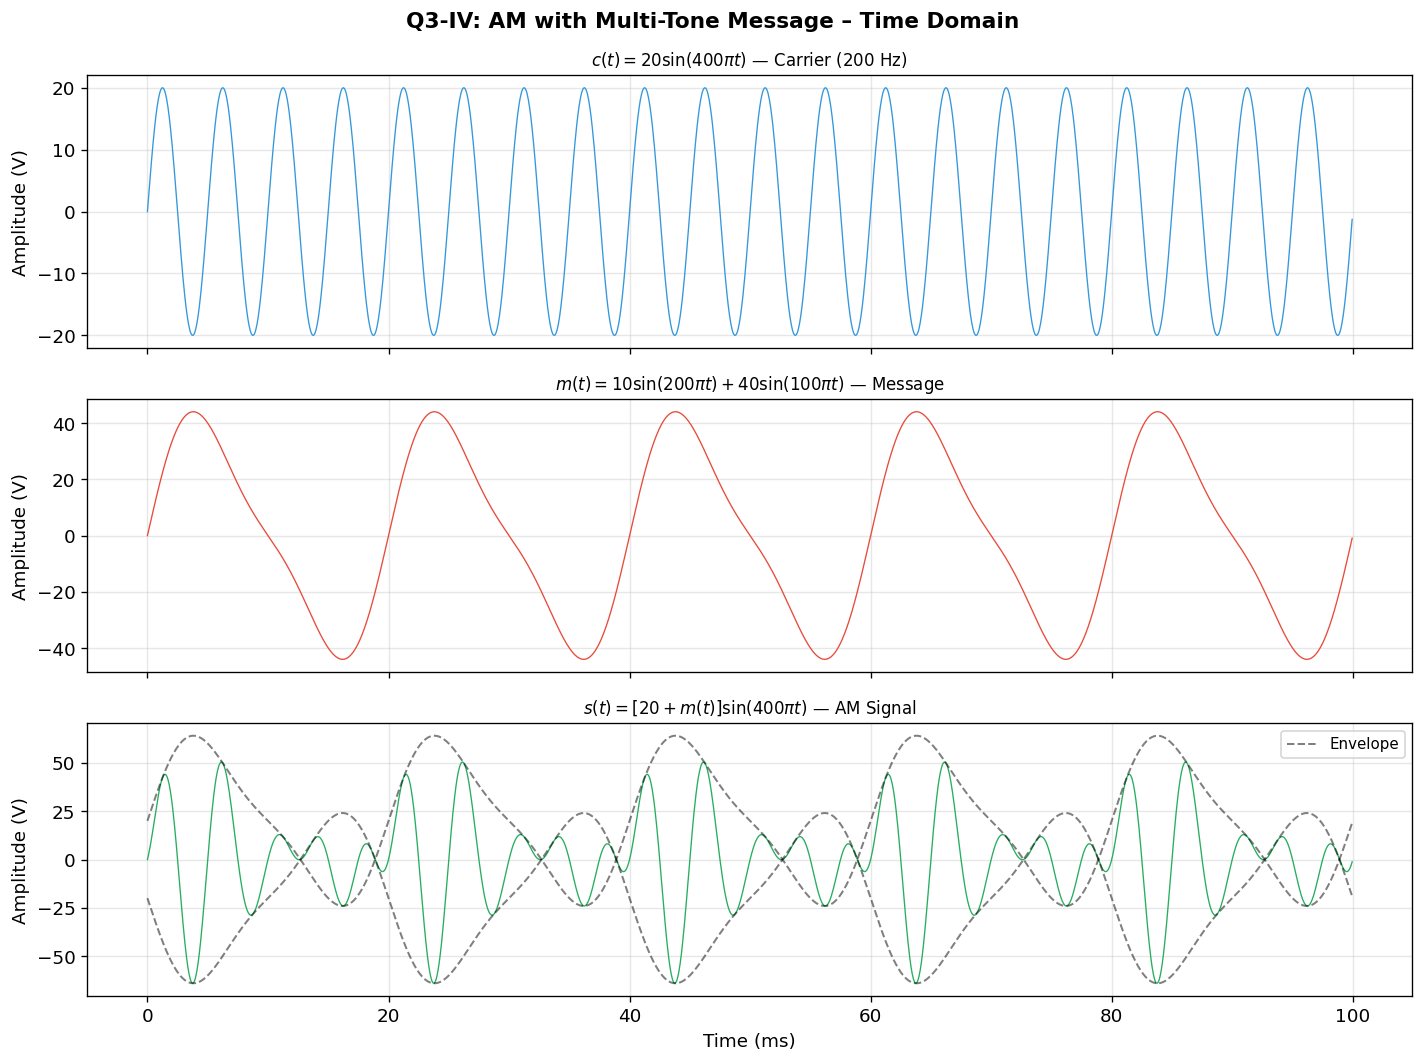

In [6]:
# Parameters
f_c4, A_c4 = 200, 20.0
f_m1, A_m1 = 100, 10.0
f_m2, A_m2 = 50,  40.0

fs4 = 20000
t4  = np.linspace(0, 0.1, int(fs4*0.1), endpoint=False)

c4 = A_c4 * np.sin(2*np.pi*f_c4*t4)
m4 = A_m1 * np.sin(2*np.pi*f_m1*t4) + A_m2 * np.sin(2*np.pi*f_m2*t4)
s4 = (A_c4 + m4) * np.sin(2*np.pi*f_c4*t4)

# (b) Time domain
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
fig.suptitle('Q3-IV: AM with Multi-Tone Message – Time Domain', fontweight='bold', fontsize=13)

for ax, y, lbl, col in zip(axes,
    [c4, m4, s4],
    [r'$c(t) = 20\sin(400\pi t)$ — Carrier (200 Hz)',
     r'$m(t) = 10\sin(200\pi t) + 40\sin(100\pi t)$ — Message',
     r'$s(t) = [20+m(t)]\sin(400\pi t)$ — AM Signal'],
    ['#3498db','#e74c3c','#27ae60']):
    ax.plot(t4*1000, y, color=col, lw=0.8)
    ax.set_title(lbl, fontsize=10)
    ax.set_ylabel('Amplitude (V)')

axes[2].plot(t4*1000,  (A_c4+m4), 'k--', lw=1.2, alpha=0.5, label='Envelope')
axes[2].plot(t4*1000, -(A_c4+m4), 'k--', lw=1.2, alpha=0.5)
axes[2].legend(fontsize=9)
axes[2].set_xlabel('Time (ms)')
plt.tight_layout()
plt.savefig('q3_iv_b_time.png', bbox_inches='tight', dpi=150)
plt.show()


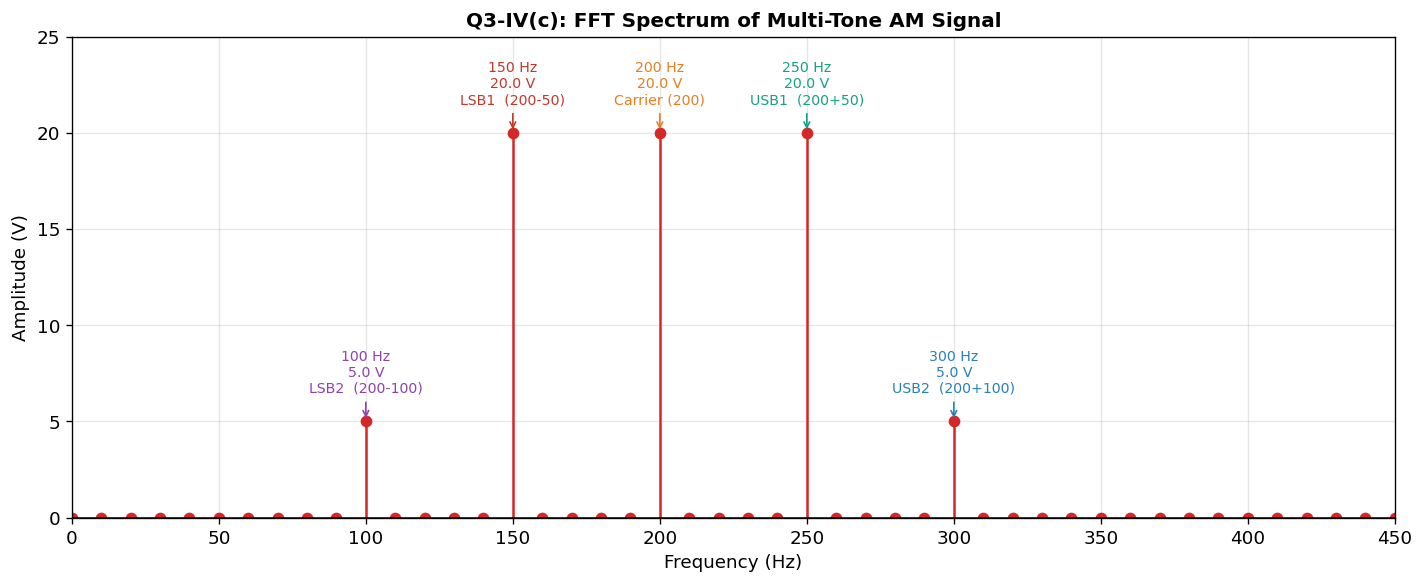

Frequency components:
  100 Hz -> 5.0 V
  150 Hz -> 20.0 V
  200 Hz -> 20.0 V
  250 Hz -> 20.0 V
  300 Hz -> 5.0 V

(ii)  Lowest  frequency : 100 Hz
(iii) Highest frequency : 300 Hz
(iv)  Bandwidth         : 200 Hz  (= 2 x f_m_max = 2 x 100)


In [7]:
# (c) FFT
N4   = len(s4)
S4   = np.fft.rfft(s4)
f4   = np.fft.rfftfreq(N4, 1/fs4)
mag4 = np.abs(S4) / N4
mag4[1:-1] *= 2

fig, ax = plt.subplots(figsize=(12, 5))
ax.stem(f4, mag4, markerfmt='C3o', linefmt='C3-', basefmt='k-')
ax.set_xlim(0, 450)
ax.set_ylim(0, 25)
ax.set_title('Q3-IV(c): FFT Spectrum of Multi-Tone AM Signal', fontweight='bold', fontsize=12)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Amplitude (V)')

exp4 = {
    100: ('LSB2  (200-100)', '#8e44ad'),
    150: ('LSB1  (200-50)',  '#c0392b'),
    200: ('Carrier (200)',   '#e67e22'),
    250: ('USB1  (200+50)',  '#16a085'),
    300: ('USB2  (200+100)', '#2980b9'),
}
for ef, (lbl, col) in exp4.items():
    idx = np.argmin(np.abs(f4 - ef))
    if mag4[idx] > 0.3:
        ax.annotate(f'{ef} Hz\n{mag4[idx]:.1f} V\n{lbl}',
                    xy=(f4[idx], mag4[idx]), xytext=(f4[idx], mag4[idx]+1.5),
                    ha='center', fontsize=8.5, color=col,
                    arrowprops=dict(arrowstyle='->', color=col))

plt.tight_layout()
plt.savefig('q3_iv_c_fft.png', bbox_inches='tight', dpi=150)
plt.show()

valid4 = [(ff, mm) for ff, mm in zip(f4, mag4) if mm > 0.5 and 0 < ff < 450]
f_lo4 = min(v[0] for v in valid4)
f_hi4 = max(v[0] for v in valid4)
print("Frequency components:")
for ff, mm in sorted(valid4): print(f"  {ff:.0f} Hz -> {mm:.1f} V")
print(f"\n(ii)  Lowest  frequency : {f_lo4:.0f} Hz")
print(f"(iii) Highest frequency : {f_hi4:.0f} Hz")
print(f"(iv)  Bandwidth         : {f_hi4-f_lo4:.0f} Hz  (= 2 x f_m_max = 2 x 100)")


#### Answers – Q3-IV(c)

| Frequency | Amplitude | Description |
|:---------:|:---------:|:------------|
| **100 Hz** | 5 V | Lower sideband 2: $f_c - f_{m1} = 200 - 100$ |
| **150 Hz** | 20 V | Lower sideband 1: $f_c - f_{m2} = 200 - 50$ |
| **200 Hz** | 20 V | Carrier frequency |
| **250 Hz** | 20 V | Upper sideband 1: $f_c + f_{m2} = 200 + 50$ |
| **300 Hz** | 5 V | Upper sideband 2: $f_c + f_{m1} = 200 + 100$ |

- **(ii) Lowest frequency:** 100 Hz  
- **(iii) Highest frequency:** 300 Hz  
- **(iv) Bandwidth:** $300 - 100 = $ **200 Hz** $= 2f_{m,\max}$  

Confirms the general AM bandwidth rule: $BW = 2f_{m,\max}$.